In [23]:
# loading all the required libs
import cv2
import pywt
import matplotlib.pyplot as plt

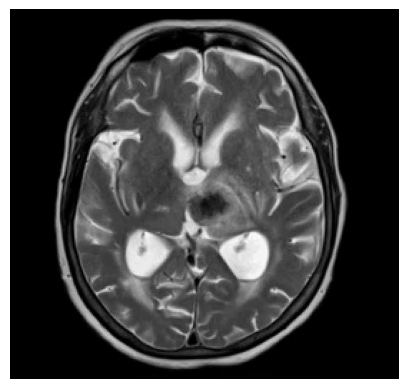

In [24]:
# loading the image and printing it
img = cv2.imread('P1.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

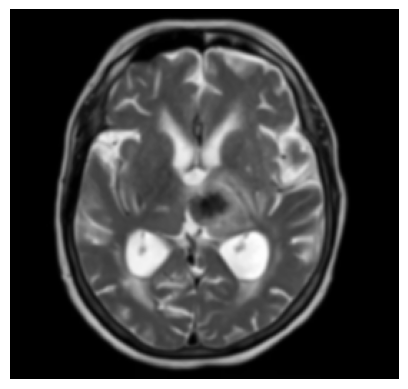

In [25]:
# removing gaussian noise using gaussian blur filter
nonoise = cv2.GaussianBlur(img, (5, 5), 0)
plt.imshow(nonoise, cmap='gray')
plt.axis('off')
plt.show()

In [26]:
# doing single level dwt and perining the szie of each shape
coeffs = pywt.dwt2(nonoise, 'haar')
LL, (LH, HL, HH) = coeffs

print(f"Original image shape: {nonoise.shape}")
print(f"LL shape: {LL.shape}")
print(f"LH shape: {LH.shape}")
print(f"HL shape: {HL.shape}")
print(f"HH shape: {HH.shape}")

Original image shape: (259, 272)
LL shape: (130, 136)
LH shape: (130, 136)
HL shape: (130, 136)
HH shape: (130, 136)


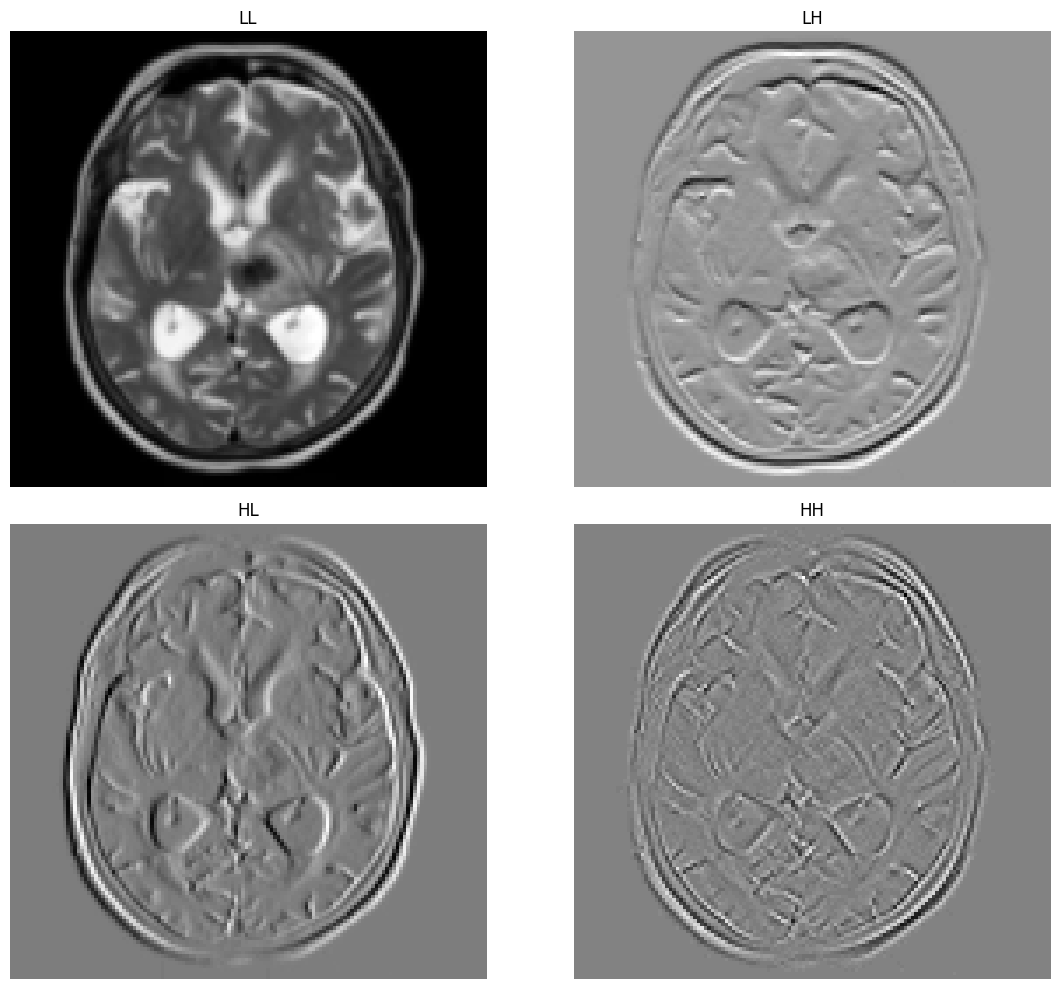

In [27]:
# prinitng the LL LH HL HH
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(LL, cmap='gray')
axes[0, 0].set_title('LL')
axes[0, 0].axis('off')

axes[0, 1].imshow(LH, cmap='gray')
axes[0, 1].set_title('LH')
axes[0, 1].axis('off')

axes[1, 0].imshow(HL, cmap='gray')
axes[1, 0].set_title('HL')
axes[1, 0].axis('off')

axes[1, 1].imshow(HH, cmap='gray')
axes[1, 1].set_title('HH')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

In [28]:
# calculating l3 dwt
coeffs_3level = pywt.wavedec2(nonoise, 'haar', level=3)

print(f"Level 3 LL shape: {coeffs_3level[0].shape}")
for i in range(1, len(coeffs_3level)):
    print(f"Level {4-i} detail coef (LH, HL, HH) shapes: {coeffs_3level[i][0].shape}")

Level 3 LL shape: (33, 34)
Level 3 detail coef (LH, HL, HH) shapes: (33, 34)
Level 2 detail coef (LH, HL, HH) shapes: (65, 68)
Level 1 detail coef (LH, HL, HH) shapes: (130, 136)


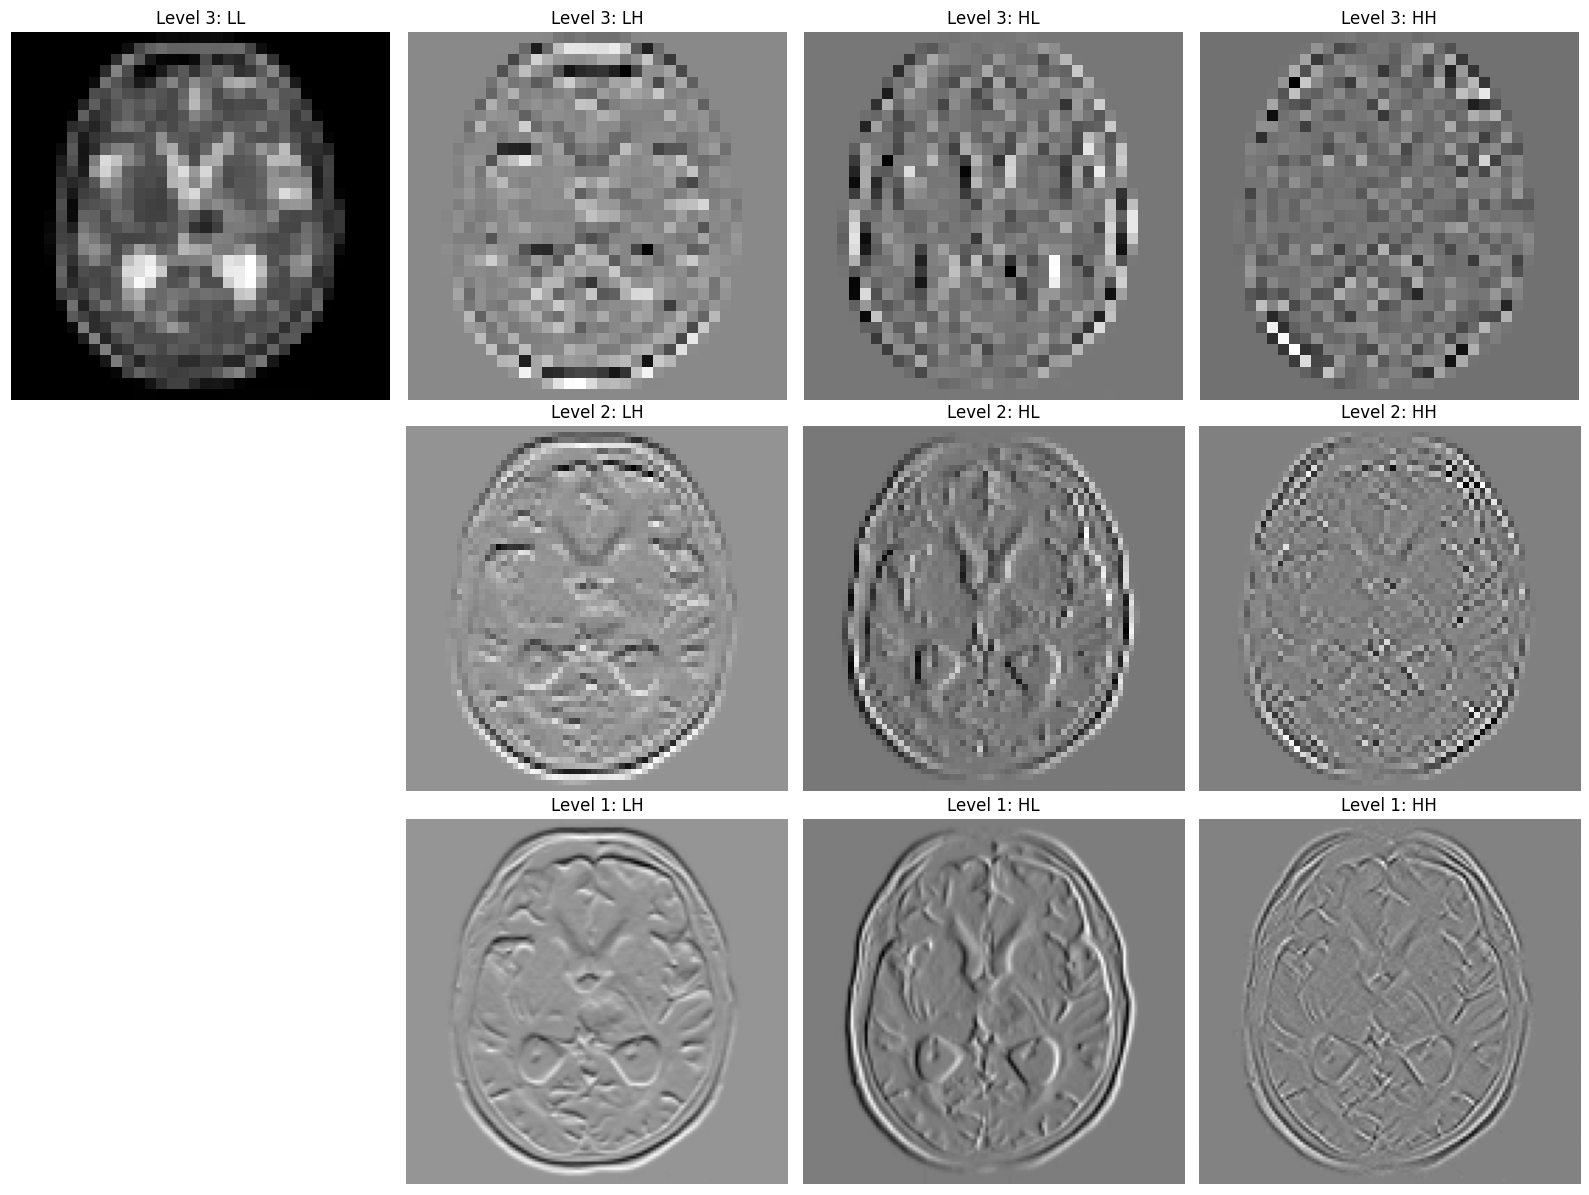

In [29]:
# printing the l3 dwt images
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes[0, 0].imshow(coeffs_3level[0], cmap='gray')
axes[0, 0].set_title('Level 3: LL')
axes[0, 0].axis('off')

axes[0, 1].imshow(coeffs_3level[1][0], cmap='gray')
axes[0, 1].set_title('Level 3: LH')
axes[0, 1].axis('off')

axes[0, 2].imshow(coeffs_3level[1][1], cmap='gray')
axes[0, 2].set_title('Level 3: HL')
axes[0, 2].axis('off')

axes[0, 3].imshow(coeffs_3level[1][2], cmap='gray')
axes[0, 3].set_title('Level 3: HH')
axes[0, 3].axis('off')

axes[1, 0].axis('off')

axes[1, 1].imshow(coeffs_3level[2][0], cmap='gray')
axes[1, 1].set_title('Level 2: LH')
axes[1, 1].axis('off')

axes[1, 2].imshow(coeffs_3level[2][1], cmap='gray')
axes[1, 2].set_title('Level 2: HL')
axes[1, 2].axis('off')

axes[1, 3].imshow(coeffs_3level[2][2], cmap='gray')
axes[1, 3].set_title('Level 2: HH')
axes[1, 3].axis('off')

axes[2, 0].axis('off')

axes[2, 1].imshow(coeffs_3level[3][0], cmap='gray')
axes[2, 1].set_title('Level 1: LH')
axes[2, 1].axis('off')

axes[2, 2].imshow(coeffs_3level[3][1], cmap='gray')
axes[2, 2].set_title('Level 1: HL')
axes[2, 2].axis('off')

axes[2, 3].imshow(coeffs_3level[3][2], cmap='gray')
axes[2, 3].set_title('Level 1: HH')
axes[2, 3].axis('off')

plt.tight_layout()
plt.show()